In [1]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import pandas as pd
import math
from scipy.integrate import solve_ivp, cumulative_trapezoid, quad, solve_bvp
from scipy.interpolate import CubicSpline
from numba import jit, njit, prange

In [2]:
# Set som plotting standards:
font = {'family' : 'serif',
        'weight' : 'normal',
        'size'   : 18}
mpl.rc('font', **font)

axes = {'facecolor': 'ghostwhite'}
mpl.rc('axes', **axes)

# Set custom color cycle
custom_colors= ['dodgerblue', 'red', 'limegreen', 'orange', 'orchid', 'black', 'slategrey', 
                'navy', 'magenta', 'forestgreen', 'lightblue', 'maroon', 'gold', 'lightcoral', 
                'mediumseagreen', 'darkorange', 'darkviolet', 'dimgray', 'darkblue', 'darkred',]
plt.rcParams['axes.prop_cycle'] = plt.cycler(color=custom_colors)

# Set inside tickmarks
mpl.rcParams['xtick.direction'] = 'in'
mpl.rcParams['ytick.direction'] = 'in'
mpl.rcParams['xtick.minor.visible'] = True
mpl.rcParams['ytick.minor.visible'] = True

In [3]:
from Functions import compute_for_sigmoidal

# Activation inside 

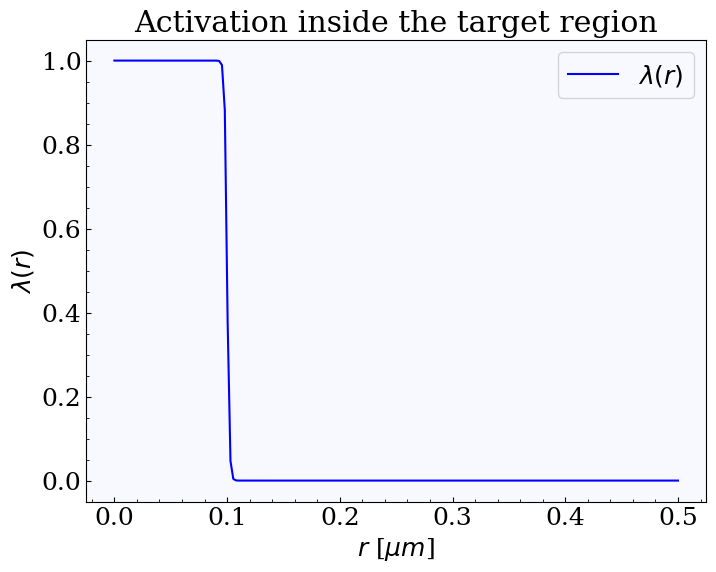

In [7]:
def activation_function(r, l0, b, rf):
    e = np.exp(-b * (r - rf))
    return l0 * e / (1 + e)

r_axis = np.linspace(0, 0.5, 200)

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(r_axis, activation_function(r_axis, l0=1.0, b=1000.0, rf=0.1), label=f'$\lambda(r)$', color='blue')
ax.set_xlabel('$r$ [$\mu m$]')
ax.set_ylabel('$\lambda(r)$')
ax.set_title('Activation inside the target region')
ax.legend()
plt.show()

# Functions

In [8]:
def compute_for_two_state(
    r_target,
    rf,
    rn,
    A,
    b,
    D0,
    Dn,
    lambda0=0.01,
    gamma=0.01,
    ndim=3,
    N=4000,
    tol=1e-4,
    max_nodes=20000,
):
    """
    Computes both T_A(r) and T_I(r) for the two-state model.

    Active state:
        -1 = LT_A - gamma * (T_A - T_I)
        T_A(r_target) = 0
        T_A'(rn) = 0

    Inactive state:
        -1 = LT_I - lambda(r) * (T_I - T_A)
        T_I'(r_target) = 0
        T_I'(rn) = 0

    where L is the generator of the diffusion process:
        Lf = D(r) f'' + mu(r) f'

    Parameters
    ----------
    r_target : float
        Target radius.
    rf : float
        Droplet radius (where the sigmoidal functions are centered).
    rn : float
        Outer reflecting boundary radius.
    A : float
        Amplitude of the sigmoidal function for the potential U(r).
    b : float
        Steepness of the sigmoidal function for the potential U(r).
    D0 : float
        Diffusion coefficient inside the droplet (r < rf).
    Dn : float
        Diffusion coefficient outside the droplet (r > rf).
    lambda0 : float, optional
        Maximum activation rate (default 0.01).
    gamma : float, optional
        Deactivation rate (default 0.01).
    ndim : int, optional
        Spatial dimension (default 3).
    N : int, optional
        Number of spatial grid points.
    tol : float, optional
        Tolerance for the solution (default 1e-4).
    max_nodes : int, optional
        Maximum number of nodes for the solver (default 20000).


    Returns
    -------
    TA_func : callable
        Interpolating function for T_A(r).
    TI_func : callable
        Interpolating function for T_I(r).
    out : dict
        Diagnostics and raw arrays.
    """

    # ------------------------------------------------------------
    # Define U(r), D(r), and related functions
    # ------------------------------------------------------------
    def exp_term(rr):
        return np.exp(-b * (rr - rf))
    
    def D_func(rr):
        e = exp_term(rr)
        return D0 + (Dn - D0) / (1 + e)
    
    def dD_func(rr):
        e = exp_term(rr)
        return (Dn - D0) * b * e / (1 + e)**2

    def dU_func(rr):
        e = exp_term(rr)
        return A * b * e / (1 + e)**2

    def drift(rr):
        return (ndim - 1) * D_func(rr) / rr + dD_func(rr) - D_func(rr) * dU_func(rr)

    def activation(rr):
        e = exp_term(rr)
        return lambda0 * e / (1 + e)

    # ============================================================
    # BVP system
    # ============================================================
    # Unknown vector:
    # y[0] = T_A
    # y[1] = T_A'
    # y[2] = T_I
    # y[3] = T_I'

    def ode_system(r, y):
        TA, dTA, TI, dTI = y

        D = D_func(r)
        mu = drift(r)
        lam = activation(r)

        # From:
        # -1 = mu dTA + D d2TA - gamma (TA - TI)
        # -1 = mu dTI + D d2TI - lambda(r) (TI - TA)
        #
        # Therefore:
        # d2TA = [ -1 - mu dTA + gamma (TA - TI) ] / D
        # d2TI = [ -1 - mu dTI + lambda(r) (TI - TA) ] / D

        ddTA = (-1.0 - mu * dTA + gamma * (TA - TI)) / D
        ddTI = (-1.0 - mu * dTI + lam   * (TI - TA)) / D

        return np.vstack((dTA, ddTA, dTI, ddTI))

    def bc(ya, yb):
        """
        Boundary conditions:
        T_A(r_target)   = 0
        T_A'(rn)  = 0
        T_I'(r_target)  = 0
        T_I'(rn)  = 0
        """
        return np.array([
            ya[0],      # T_A(r_target) = 0
            yb[1],      # T_A'(rn) = 0
            ya[3],      # T_I'(r_target) = 0
            yb[3],      # T_I'(rn) = 0
        ])
    
    # ============================================================
    # Initial mesh and guess
    # ============================================================

    r_mesh = np.linspace(r_target, rn, N)

    # A simple initial guess:
    L = rn - r_target
    x = (r_mesh - r_target) / L

    TA_guess = L**2 * (2*x - x**2)   # TA(r_target)=0, TA'(rn)=0
    dTA_guess = 2*L*(1 - x)

    TI_guess = np.full_like(r_mesh, L**2)   # constant => derivative zero at both ends
    dTI_guess = np.zeros_like(r_mesh)

    y_guess = np.vstack((TA_guess, dTA_guess, TI_guess, dTI_guess))

    # ============================================================
    # Solve the boundary value problem
    # ============================================================

    sol = solve_bvp(ode_system, bc, r_mesh, y_guess, tol=tol, max_nodes=max_nodes)

    if not sol.success:
        raise RuntimeError(f"BVP solver failed: {sol.message}")
   
    # ============================================================
    # Evaluate and interpolate solutions
    # ============================================================
        
    r_eval = np.linspace(r_target, rn, 1000)
    TA_sol = sol.sol(r_eval)[0]
    TI_sol = sol.sol(r_eval)[2]

    TA_spline = CubicSpline(r_eval, TA_sol, bc_type="natural", extrapolate=False)
    TI_spline = CubicSpline(r_eval, TI_sol, bc_type="natural", extrapolate=False)
    
    def TA_func(r):
        r = np.asarray(r)
        if np.any((r < r_target) | (r > rn)):
            raise ValueError("r must lie within [r_target, rn].")
        return TA_spline(r)

    def TI_func(r):
        r = np.asarray(r)
        if np.any((r < r_target) | (r > rn)):
            raise ValueError("r must lie within [r_target, rn].")
        return TI_spline(r)

    out = {
        "r_grid": r_eval,
        "TA_values": TA_sol,
        "TI_values": TI_sol,
        "TA_rn": float(TA_spline(rn)),
        "TI_rn": float(TI_spline(rn)),
        "drift": drift,
        "lambda_values": activation(r_eval),
    }

    return TA_func, TI_func, out

In [9]:
# ──────────────────────────────────────────────────────────────────────────────
# Numba-compiled helpers for simulation (no Python objects, no closures — plain scalars only)
# ──────────────────────────────────────────────────────────────────────────────

@njit(cache=True)
def _exp_term(r, b, rf):
    return np.exp(-b * (r - rf))

@njit(cache=True)
def _D_func(r, b, rf, D0, Dn):
    e = _exp_term(r, b, rf)
    return D0 + (Dn - D0) / (1.0 + e)

@njit(cache=True)
def _dD_func(r, b, rf, D0, Dn):
    e = _exp_term(r, b, rf)
    return (Dn - D0) * b * e / (1.0 + e) ** 2

@njit(cache=True)
def _dU_func(r, b, rf, A):
    e = _exp_term(r, b, rf)
    return A * b * e / (1.0 + e) ** 2

@njit(cache=True)
def _mu_func(r, b, rf, A, D0, Dn, ndim):
    D  = _D_func(r, b, rf, D0, Dn)
    dD = _dD_func(r, b, rf, D0, Dn)
    dU = _dU_func(r, b, rf, A)
    return (ndim - 1) * D / r + dD - D * dU

@njit(cache=True)
def _lambda_func(r, b, rf, lambda0):
    e = _exp_term(r, b, rf)
    return lambda0 * e / (1.0 + e)

@njit(cache=True)
def _t_step(r, dt_max, alpha, b, rf, A):
    e = _exp_term(r, b, rf)
    return dt_max / (1.0 + alpha * np.abs(A * b * e / (1.0 + e) ** 2))


@njit(cache=True, parallel=True)
def _run_trajectories(
    r0, state0, r_target, rf, rn,
    A, b, D0, Dn, lambda0, gamma,
    dt_max, alpha, 
    ndim, n_trajectories, max_steps,
):
    """
    Core simulation loop — fully compiled and parallelised across trajectories.
    Includes adaptive time stepping based on local potential gradients.

    Returns
    -------
    fpt_samples : float64 array, length n_trajectories
        NaN for trajectories that did not complete.
    """
    #sqrt_dt = np.sqrt(dt)
    fpt_samples = np.full(n_trajectories, np.nan)

    for traj in prange(n_trajectories):          # parallel across trajectories
        r     = r0
        state = state0                           # active (1) or inactive (0)
        t     = 0.0

        for _ in range(max_steps):

            # Compute adaptive time step based on local rates of change
            delta_t = _t_step(r, dt_max=dt_max, alpha=alpha, b=b, rf=rf, A=A)
            sqrt_dt = math.sqrt(delta_t)

            # Compute switching rate at current position and update state
            if state == 0:
                rate = _lambda_func(r, b, rf, lambda0)   # I -> A
            else:
                rate = gamma                              # A -> I

            if rate > 0.0:
                p_switch = 1.0 - math.exp(-rate * delta_t)
                if np.random.rand() < p_switch:
                    state = 1 - state

            D  = _D_func(r, b, rf, D0, Dn)
            mu = _mu_func(r, b, rf, A, D0, Dn, ndim)
            

            # Euler–Maruyama step
            r_new = r + mu * delta_t + np.sqrt(2.0 * D) * sqrt_dt * np.random.standard_normal()

            # Reflect at outer boundary
            if r_new > rn:
                r_new = 2.0 * rn - r_new

            t += delta_t

            if r_new <= r_target:
                if state == 1:
                    # Absorb
                    frac = (r - r_target) / (r - r_new)
                    fpt_samples[traj] = (t - delta_t) + frac * delta_t
                    break
                else:
                    # Reflect inactive particle
                    r_new = 2.0 * r_target - r_new

            r = r_new
        

    return fpt_samples


# ──────────────────────────────────────────────────────────────────────────────
# Public API  (matches the original signature exactly)
# ──────────────────────────────────────────────────────────────────────────────

def simulate_two_state_mfpt(
    r0: float,
    state0: int,
    r_target: float,
    rf: float,
    rn: float,
    A: float,
    b: float,
    D0: float,
    Dn: float,
    lambda0: float = 0.01,
    gamma: float = 0.01,
    dt_max: float = 1e-4,
    alpha: float = 0.05,
    ndim: int = 3,
    n_trajectories: int = 1000,
    max_steps: int = 10_000_000,
    seed: int | None = None,
) -> dict:
    """
    Numba-accelerated two-state MFPT simulator.

    Parameters are identical to the pure-Python version.
    `rng` is replaced by `seed` (int or None) because Numba uses its own
    internal RNG seeded via np.random.seed().
    """
    if seed is not None:
        np.random.seed(seed)

    fpt_samples = _run_trajectories(
        r0, state0, r_target, rf, rn,
        A, b, D0, Dn, lambda0, gamma,
        dt_max, alpha, 
        ndim, n_trajectories, max_steps,
    )

    completed  = fpt_samples[~np.isnan(fpt_samples)]
    n_completed  = len(completed)
    n_truncated  = n_trajectories - n_completed

    return {
        "mean_fpt"   : float(np.mean(completed))                          if n_completed > 0 else np.nan,
        "std_fpt"    : float(np.std(completed))                           if n_completed > 0 else np.nan,
        "stderr_fpt" : float(np.std(completed) / np.sqrt(n_completed))   if n_completed > 1 else np.nan,
        "fpt_samples": completed,
        "n_completed": n_completed,
        "n_truncated": n_truncated,
    }

In [10]:
# Parameters for computation
r_target = 0.01
rf = 0.1
rn = 0.5
A = 5.0
b = 1000.0
D0 = 0.2
Dn = 0.8
D = 0.5

lambda0 = 10.0
gamma = 0.5

# Estimate regime of interest for MFPT
L = rn - r_target
diffusion_time_scale = L**2 / D

print(f"Estimated diffusion time scale: {1/diffusion_time_scale:.2f}")
print(f"Estimated activation time scale: {lambda0:.2f}")
print(f"Estimated deactivation time scale: {gamma:.2f}")

Estimated diffusion time scale: 2.08
Estimated activation time scale: 10.00
Estimated deactivation time scale: 0.50


# Constant Diffusion

In [275]:
# Scaling with diffusion coefficient D (keeping D0 = Dn = D for simplicity)

r_target = 0.01
rn = 0.5
A = 5.0
b = 1000.0

lambda0 = 0.1
gamma = 0.1

rf_vals = np.linspace(0.15, 0.3, 50)
D_vals = np.linspace(0.05, 3.5, 20)

T_A = np.zeros((len(D_vals), len(rf_vals)))
T_I = np.zeros((len(D_vals), len(rf_vals)))

for i in range(len(D_vals)):
    for j in range(len(rf_vals)):
        TA_func, TI_func, out = compute_for_two_state(
            r_target=r_target,
            rf=rf_vals[j],
            rn=rn,
            A=A,
            b=b,
            D0=D_vals[i],
            Dn=D_vals[i],
            lambda0=lambda0,
            gamma=gamma,
            ndim=3,
            N=300,
            tol=1e-6,
            max_nodes=20000,
        )
        T_A[i, j] = out["TA_rn"]
        T_I[i, j] = out["TI_rn"]


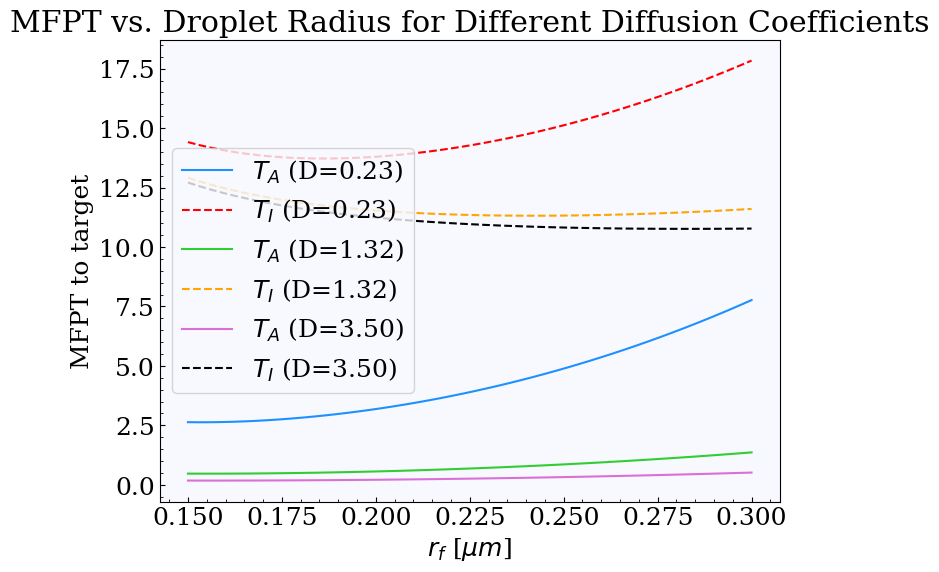

In [276]:
# Plot the mfpt as a function of rf for a few different D values

sel_D_idx = [1, 7, 19] #[17, 18, 19]

fig, ax = plt.subplots(figsize=(8, 6))
for i in sel_D_idx:
    ax.plot(rf_vals, T_A[i, :], label=f'$T_A$ (D={D_vals[i]:.2f})')
    ax.plot(rf_vals, T_I[i, :], label=f'$T_I$ (D={D_vals[i]:.2f})', linestyle='--')
ax.set_xlabel('$r_f$ [$\mu m$]')
ax.set_ylabel('MFPT to target')
ax.set_title('MFPT vs. Droplet Radius for Different Diffusion Coefficients')
ax.legend()
plt.show()

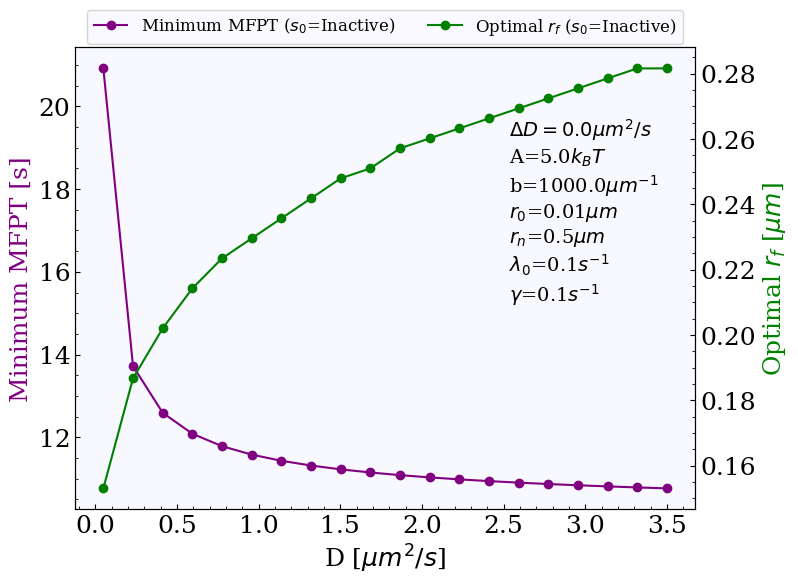

In [288]:
# Extract the optimal rf value and the corresponding MFPT for each D value
min_mfpt_D_I = np.min(T_I, axis=1)
optimal_rf_D_I = rf_vals[np.argmin(T_I, axis=1)]
min_mfpt_D_A = np.min(T_A, axis=1)
optimal_rf_D_A = rf_vals[np.argmin(T_A, axis=1)]

# Plot the minimum mfpt as a function of D 
fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(D_vals, min_mfpt_D_I, '-o', color='purple', label='Minimum MFPT ($s_0$=Inactive)')
ax.set_xlabel('D [$\mu m^2/s$]')
ax.set_ylabel('Minimum MFPT [s]', color='purple')

# On a secondary y-axis, plot the optimal rf value as a function of D
ax2 = ax.twinx()
ax2.plot(D_vals, optimal_rf_D_I, '-o', color='green', label='Optimal $r_f$ ($s_0$=Inactive)')
#ax2.axhline(rn, color='r', linestyle='--', label='$r_n$ (Nucleus)')
ax2.set_ylabel('Optimal $r_f$ [$\mu m$]', color='green')

# Make a single legend for both plots
lines, labels = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax2.legend(lines + lines2, labels + labels2, fontsize=12, bbox_to_anchor=(0.5, 1.1), loc='upper center', ncol=3)

# Put paramater values on the plot
text = (f'$\Delta D=0.0\mu m^2/s$\n' +
          f'A={A}$k_BT$\n' +
          f'b={b}$\mu m^{{-1}}$\n' +
          f'$r_0$={r_target}$\mu m$\n' + 
          f'$r_n$={rn}$\mu m$\n' + 
          f'$\lambda_0$={lambda0}$s^{{-1}}$\n' +
          f'$\gamma$={gamma}$s^{{-1}}$')

ax.text(0.7, 0.85, text, transform=ax.transAxes, verticalalignment='top', fontsize=14)

plt.show()

In [279]:
optimal_rf_D_I

array([0.15306122, 0.18673469, 0.20204082, 0.21428571, 0.22346939,
       0.22959184, 0.23571429, 0.24183673, 0.24795918, 0.25102041,
       0.25714286, 0.26020408, 0.26326531, 0.26632653, 0.26938776,
       0.27244898, 0.2755102 , 0.27857143, 0.28163265, 0.28163265])

In [138]:
# Scaling with potential strength A (keeping D0 = Dn = D for simplicity)

rf_vals = np.linspace(0.1, rn, 20)
A_vals = np.linspace(0.5, 10, 20)
fixed_D = 0.05
lambda0 = 0.01
gamma = 0.01

T_A_A = np.zeros((len(A_vals), len(rf_vals)))
T_I_A = np.zeros((len(A_vals), len(rf_vals)))
T_single_A = np.zeros((len(A_vals), len(rf_vals)))

for i in range(len(A_vals)):
    for j in range(len(rf_vals)):
        TA_func, TI_func, out = compute_for_two_state(
            r_target=r_target,
            rf=rf_vals[j],
            rn=rn,
            A=A_vals[i],
            b=b,
            D0=fixed_D,
            Dn=fixed_D,
            lambda0=lambda0,
            gamma=gamma,
            ndim=3,
            N=300,
            tol=1e-6,
            max_nodes=20000,
        )
        T_A_A[i, j] = out["TA_rn"]
        T_I_A[i, j] = out["TI_rn"]

/var/folders/g5/x6l6jbcj4tb_kz1_c88z7rlc0000gn/T/ipykernel_16306/805333349.py:84: RuntimeWarning: overflow encountered in square
  return (Dn - D0) * b * e / (1 + e)**2
/var/folders/g5/x6l6jbcj4tb_kz1_c88z7rlc0000gn/T/ipykernel_16306/805333349.py:88: RuntimeWarning: overflow encountered in square
  return A * b * e / (1 + e)**2


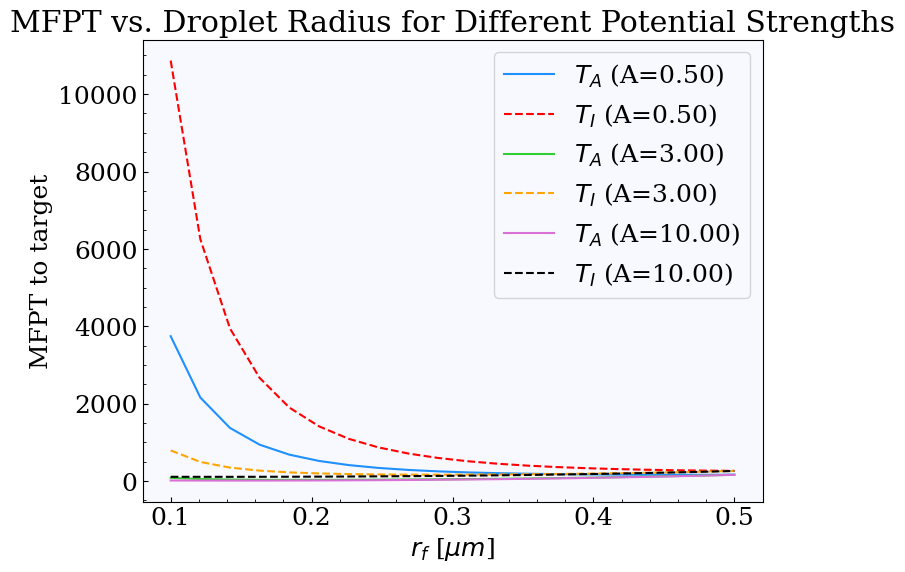

In [139]:
# Plot the mfpt as a function of rf for a few different A values

sel_A_idx = [0, 5, 19]

fig, ax = plt.subplots(figsize=(8, 6))
for i in sel_A_idx:
    ax.plot(rf_vals, T_A_A[i, :], label=f'$T_A$ (A={A_vals[i]:.2f})')
    ax.plot(rf_vals, T_I_A[i, :], label=f'$T_I$ (A={A_vals[i]:.2f})', linestyle='--')
ax.set_xlabel('$r_f$ [$\mu m$]')
ax.set_ylabel('MFPT to target')
ax.set_title('MFPT vs. Droplet Radius for Different Potential Strengths')
ax.legend()
plt.show()

In [137]:
optimal_rf_A_I

array([0.25      , 0.25      , 0.25      , 0.25      , 0.25      ,
       0.25      , 0.25      , 0.23947368, 0.22894737, 0.20789474,
       0.19736842, 0.17631579, 0.16578947, 0.15526316, 0.15526316,
       0.14473684, 0.13421053, 0.13421053, 0.13421053, 0.12368421])

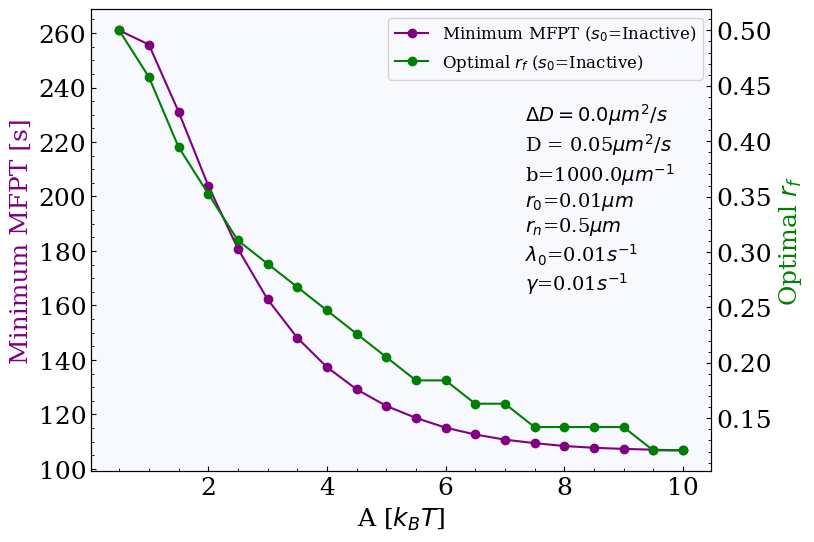

In [140]:
# Extract the optimal rf value and the corresponding MFPT for each D value
min_mfpt_A_I = np.min(T_I_A, axis=1)
optimal_rf_A_I = rf_vals[np.argmin(T_I_A, axis=1)]
min_mfpt_A_A = np.min(T_A_A, axis=1)
optimal_rf_A_A = rf_vals[np.argmin(T_A_A, axis=1)]

# Plot the minimum mfpt as a function of D 
fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(A_vals, min_mfpt_A_I, '-o', color='purple', label='Minimum MFPT ($s_0$=Inactive)')
#ax.plot(A_vals, min_mfpt_A_A, '-o', color='orange', label='Minimum MFPT ($s_0$=Active)')
ax.set_xlabel('A [$k_BT$]')
ax.set_ylabel('Minimum MFPT [s]', color='purple')

# On a secondary y-axis, plot the optimal rf value as a function of D
ax2 = ax.twinx()
ax2.plot(A_vals, optimal_rf_A_I, '-o', color='green', label='Optimal $r_f$ ($s_0$=Inactive)')
#ax2.plot(A_vals, optimal_rf_A_A, '-o', color='red', label='Optimal $r_f$ ($s_0$=Active)')
ax2.set_ylabel('Optimal $r_f$', color='green')

# Make a single legend for both plots
lines, labels = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax2.legend(lines + lines2, labels + labels2, loc='upper right', fontsize=12)

# Put paramater values on the plot
text = (f'$\Delta D=0.0\mu m^2/s$\n' +
        f'D = {fixed_D}$\mu m^2/s$\n' +
          f'b={b}$\mu m^{{-1}}$\n' +
          f'$r_0$={r_target}$\mu m$\n' + 
          f'$r_n$={rn}$\mu m$\n' + 
          f'$\lambda_0$={lambda0}$s^{{-1}}$\n' +
          f'$\gamma$={gamma}$s^{{-1}}$')

ax.text(0.7, 0.8, text, transform=ax.transAxes, verticalalignment='top', fontsize=14)

plt.show()

# Heterogeneous Diffusion

In [ ]:
# Scaling with diffusion coefficient inside droplet D0 (keeping Dn fixed)

r_target = 0.01
rn = 0.5
A = 1.0
b = 1000.0

lambda0 = 10.0
gamma = 10.0

rf_vals = np.linspace(0.1, 0.33, 20)
Dn_fixed = 1.0
D0_vals = np.linspace(0.05, Dn_fixed, 20)

T_A_D0 = np.zeros((len(D0_vals), len(rf_vals)))
T_I_D0 = np.zeros((len(D0_vals), len(rf_vals)))

for i in range(len(D0_vals)):
    for j in range(len(rf_vals)):
        TA_func, TI_func, out = compute_for_two_state(
            r_target=r_target,
            rf=rf_vals[j],
            rn=rn,
            A=A,
            b=b,
            D0=D0_vals[i],
            Dn=Dn_fixed,
            lambda0=lambda0,
            gamma=gamma,
            ndim=3,
            N=300,
            tol=1e-6,
            max_nodes=25000,
        )
        T_A_D0[i, j] = out["TA_rn"]
        T_I_D0[i, j] = out["TI_rn"]

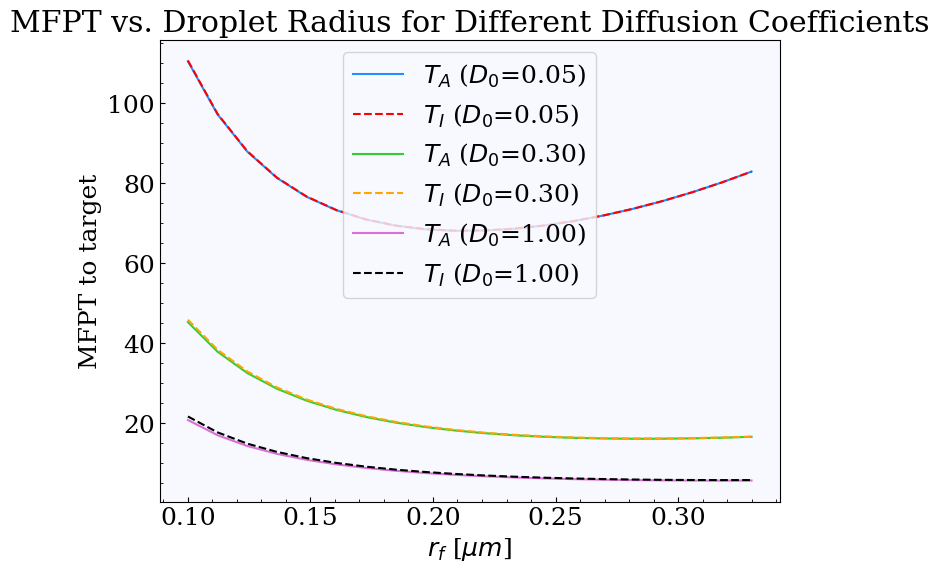

In [192]:
# Plot the mfpt as a function of rf for a few different D values

sel_D_idx = [0, 5, 19]

fig, ax = plt.subplots(figsize=(8, 6))
for i in sel_D_idx:
    ax.plot(rf_vals, T_A_D0[i, :], label=f'$T_A$ ($D_0$={D0_vals[i]:.2f})')
    ax.plot(rf_vals, T_I_D0[i, :], label=f'$T_I$ ($D_0$={D0_vals[i]:.2f})', linestyle='--')
ax.set_xlabel('$r_f$ [$\mu m$]')
ax.set_ylabel('MFPT to target')
ax.set_title('MFPT vs. Droplet Radius for Different Diffusion Coefficients')
ax.legend()
plt.show()

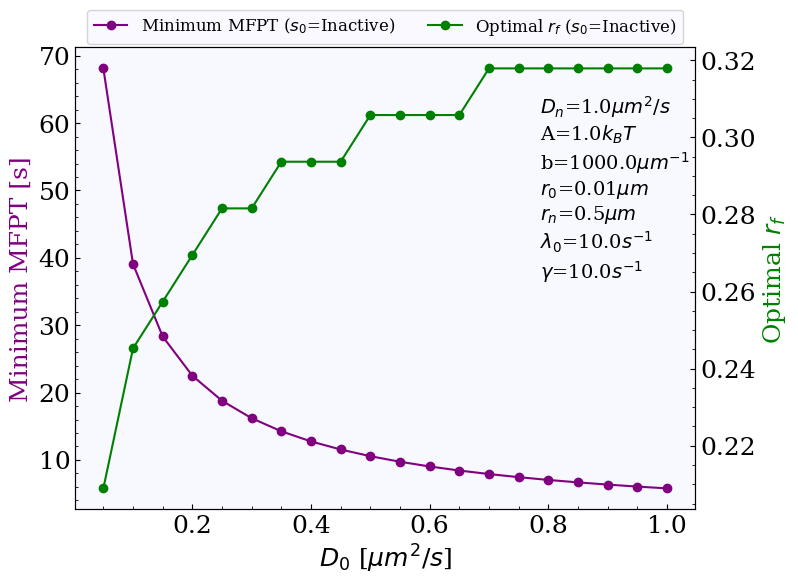

In [194]:
# Extract the optimal rf value and the corresponding MFPT for each D value
min_mfpt_D_I = np.min(T_I_D0, axis=1)
optimal_rf_D_I = rf_vals[np.argmin(T_I_D0, axis=1)]
min_mfpt_D_A = np.min(T_A_D0, axis=1)
optimal_rf_D_A = rf_vals[np.argmin(T_A_D0, axis=1)]

# Plot the minimum mfpt as a function of D 
fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(D0_vals, min_mfpt_D_I, '-o', color='purple', label='Minimum MFPT ($s_0$=Inactive)')
#ax.plot(D0_vals, min_mfpt_D_A, '-o', color='orange', label='Minimum MFPT ($s_0$=Active)')
ax.set_xlabel('$D_0$ [$\mu m^2/s$]')
ax.set_ylabel('Minimum MFPT [s]', color='purple')

# On a secondary y-axis, plot the optimal rf value as a function of D
ax2 = ax.twinx()
ax2.plot(D0_vals, optimal_rf_D_I, '-o', color='green', label='Optimal $r_f$ ($s_0$=Inactive)')
#ax2.plot(D0_vals, optimal_rf_D_A, '-o', color='red', ms=2, label='Optimal $r_f$ ($s_0$=Active)')
ax2.set_ylabel('Optimal $r_f$', color='green')

# Make a single legend for both plots
lines, labels = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax2.legend(lines + lines2, labels + labels2, fontsize=12, bbox_to_anchor=(0.5, 1.1), loc='upper center', ncol=2)

# Put paramater values on the plot
text = (f'$D_n$={Dn_fixed}$\mu m^2/s$\n' +
          f'A={A}$k_BT$\n' +
          f'b={b}$\mu m^{{-1}}$\n' +
          f'$r_0$={r_target}$\mu m$\n' + 
          f'$r_n$={rn}$\mu m$\n' + 
          f'$\lambda_0$={lambda0}$s^{{-1}}$\n' +
          f'$\gamma$={gamma}$s^{{-1}}$')

ax.text(0.75, 0.9, text, transform=ax.transAxes, verticalalignment='top', fontsize=14)

plt.show()

In [228]:
# Scaling with diffusion coefficient outside droplet Dn (keeping D0 fixed)

r_target = 0.01
rn = 0.5
A = 5.0
b = 1000.0

lambda0 = 0.01
gamma = 0.01

rf_vals = np.linspace(0.19, 0.22, 20)
D0_fixed = 0.05
Dn_vals = np.linspace(D0_fixed, 2.0, 20)

T_A_Dn = np.zeros((len(Dn_vals), len(rf_vals)))
T_I_Dn = np.zeros((len(Dn_vals), len(rf_vals)))

for i in range(len(Dn_vals)):
    for j in range(len(rf_vals)):
        TA_func, TI_func, out = compute_for_two_state(
            r_target=r_target,
            rf=rf_vals[j],
            rn=rn,
            A=A,
            b=b,
            D0=D0_fixed,
            Dn=Dn_vals[i],
            lambda0=lambda0,
            gamma=gamma,
            ndim=3,
            N=300,
            tol=1e-6,
            max_nodes=25000,
        )
        T_A_Dn[i, j] = out["TA_rn"]
        T_I_Dn[i, j] = out["TI_rn"]

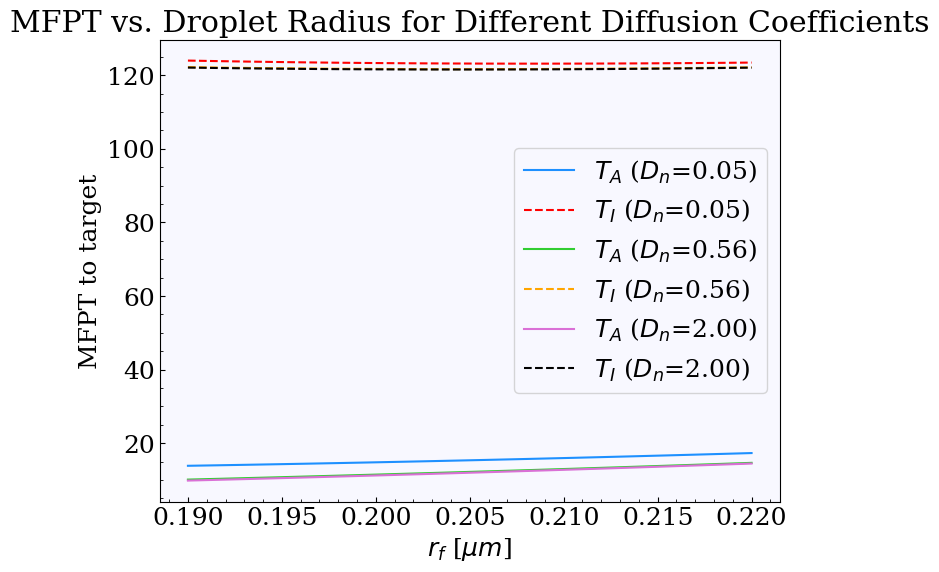

In [229]:
# Plot the mfpt as a function of rf for a few different D values

sel_D_idx = [0, 5, 19]

fig, ax = plt.subplots(figsize=(8, 6))
for i in sel_D_idx:
    ax.plot(rf_vals, T_A_Dn[i, :], label=f'$T_A$ ($D_n$={Dn_vals[i]:.2f})')
    ax.plot(rf_vals, T_I_Dn[i, :], label=f'$T_I$ ($D_n$={Dn_vals[i]:.2f})', linestyle='--')
ax.set_xlabel('$r_f$ [$\mu m$]')
ax.set_ylabel('MFPT to target')
ax.set_title('MFPT vs. Droplet Radius for Different Diffusion Coefficients')
ax.legend()
plt.show()

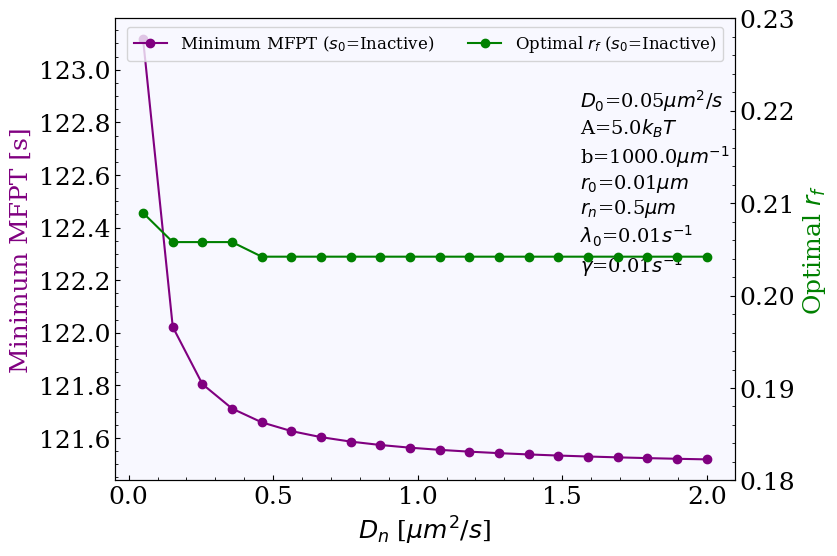

In [231]:
# Extract the optimal rf value and the corresponding MFPT for each D value
min_mfpt_D_I = np.min(T_I_Dn, axis=1)
optimal_rf_D_I = rf_vals[np.argmin(T_I_Dn, axis=1)]
min_mfpt_D_A = np.min(T_A_Dn, axis=1)
optimal_rf_D_A = rf_vals[np.argmin(T_A_Dn, axis=1)]

# Plot the minimum mfpt as a function of D 
fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(Dn_vals, min_mfpt_D_I, '-o', color='purple', label='Minimum MFPT ($s_0$=Inactive)')
#ax.plot(Dn_vals, min_mfpt_D_A, '-o', color='orange', label='Minimum MFPT ($s_0$=Active)')
ax.set_xlabel('$D_n$ [$\mu m^2/s$]')
ax.set_ylabel('Minimum MFPT [s]', color='purple')

# On a secondary y-axis, plot the optimal rf value as a function of D
ax2 = ax.twinx()
ax2.plot(Dn_vals, optimal_rf_D_I, '-o', color='green', label='Optimal $r_f$ ($s_0$=Inactive)')
#ax2.plot(Dn_vals, optimal_rf_D_A, '-o', color='red', ms=2, label='Optimal $r_f$ ($s_0$=Active)')
ax2.set_ylabel('Optimal $r_f$', color='green')
ax2.set_ylim(0.18, 0.23)

# Make a single legend for both plots
lines, labels = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax2.legend(lines + lines2, labels + labels2, fontsize=12, bbox_to_anchor=(0.5, 1.0), loc='upper center', ncol=2)

# Put paramater values on the plot
text = (f'$D_0$={D0_fixed}$\mu m^2/s$\n' +
          f'A={A}$k_BT$\n' +
          f'b={b}$\mu m^{{-1}}$\n' +
          f'$r_0$={r_target}$\mu m$\n' + 
          f'$r_n$={rn}$\mu m$\n' + 
          f'$\lambda_0$={lambda0}$s^{{-1}}$\n' +
          f'$\gamma$={gamma}$s^{{-1}}$')

ax.text(0.75, 0.85, text, transform=ax.transAxes, verticalalignment='top', fontsize=14)

plt.show()

In [232]:
Dn_fixed

1.0

In [233]:
# Scaling with potential strength A 

rf_vals = np.linspace(0.1, rn, 20)
A_vals = np.linspace(0.5, 10, 20)

lambda0 = 0.01
gamma = 0.01

T_A_A1 = np.zeros((len(A_vals), len(rf_vals)))
T_I_A1 = np.zeros((len(A_vals), len(rf_vals)))

for i in range(len(A_vals)):
    for j in range(len(rf_vals)):
        TA_func, TI_func, out = compute_for_two_state(
            r_target=r_target,
            rf=rf_vals[j],
            rn=rn,
            A=A_vals[i],
            b=b,
            D0=D0_fixed,
            Dn=Dn_fixed,
            lambda0=lambda0,
            gamma=gamma,
            ndim=3,
            N=300,
            tol=1e-6,
            max_nodes=20000,
        )
        T_A_A1[i, j] = out["TA_rn"]
        T_I_A1[i, j] = out["TI_rn"]

/var/folders/g5/x6l6jbcj4tb_kz1_c88z7rlc0000gn/T/ipykernel_16306/805333349.py:84: RuntimeWarning: overflow encountered in square
  return (Dn - D0) * b * e / (1 + e)**2
/var/folders/g5/x6l6jbcj4tb_kz1_c88z7rlc0000gn/T/ipykernel_16306/805333349.py:88: RuntimeWarning: overflow encountered in square
  return A * b * e / (1 + e)**2


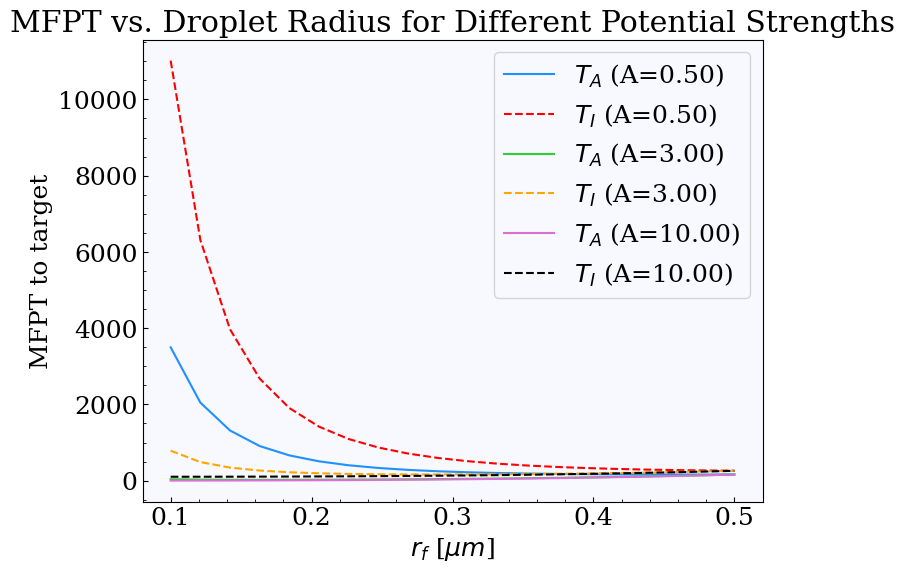

In [234]:
# Plot the mfpt as a function of rf for a few different A values

sel_A_idx = [0, 5, 19]

fig, ax = plt.subplots(figsize=(8, 6))
for i in sel_A_idx:
    ax.plot(rf_vals, T_A_A1[i, :], label=f'$T_A$ (A={A_vals[i]:.2f})')
    ax.plot(rf_vals, T_I_A1[i, :], label=f'$T_I$ (A={A_vals[i]:.2f})', linestyle='--')
ax.set_xlabel('$r_f$ [$\mu m$]')
ax.set_ylabel('MFPT to target')
ax.set_title('MFPT vs. Droplet Radius for Different Potential Strengths')
ax.legend()
plt.show()

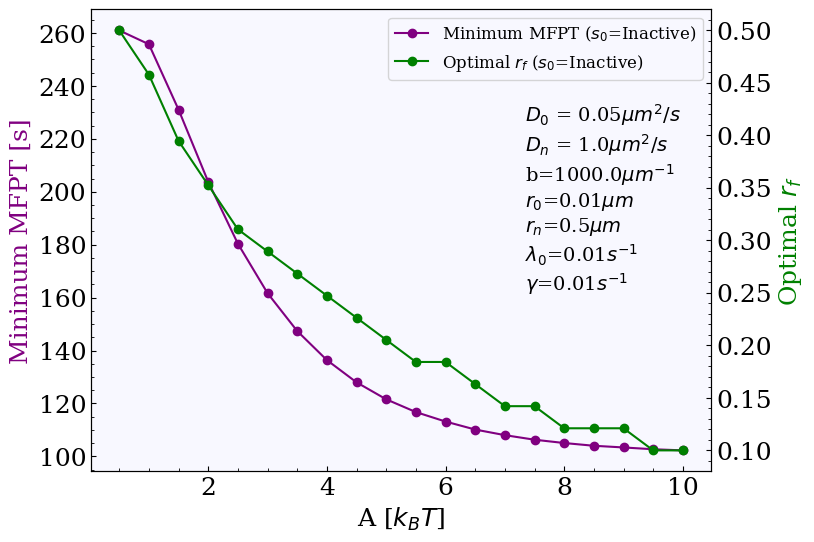

In [235]:
# Extract the optimal rf value and the corresponding MFPT for each D value
min_mfpt_A_I = np.min(T_I_A1, axis=1)
optimal_rf_A_I = rf_vals[np.argmin(T_I_A1, axis=1)]
min_mfpt_A_A = np.min(T_A_A1, axis=1)
optimal_rf_A_A = rf_vals[np.argmin(T_A_A1, axis=1)]

# Plot the minimum mfpt as a function of D 
fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(A_vals, min_mfpt_A_I, '-o', color='purple', label='Minimum MFPT ($s_0$=Inactive)')
#ax.plot(A_vals, min_mfpt_A_A, '-o', color='orange', label='Minimum MFPT ($s_0$=Active)')
ax.set_xlabel('A [$k_BT$]')
ax.set_ylabel('Minimum MFPT [s]', color='purple')

# On a secondary y-axis, plot the optimal rf value as a function of D
ax2 = ax.twinx()
ax2.plot(A_vals, optimal_rf_A_I, '-o', color='green', label='Optimal $r_f$ ($s_0$=Inactive)')
#ax2.plot(A_vals, optimal_rf_A_A, '-o', color='red', label='Optimal $r_f$ ($s_0$=Active)')
ax2.set_ylabel('Optimal $r_f$', color='green')

# Make a single legend for both plots
lines, labels = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax2.legend(lines + lines2, labels + labels2, loc='upper right', fontsize=12)

# Put paramater values on the plot
text = (f'$D_0$ = {D0_fixed}$\mu m^2/s$\n' +
        f'$D_n$ = {Dn_fixed}$\mu m^2/s$\n' +
          f'b={b}$\mu m^{{-1}}$\n' +
          f'$r_0$={r_target}$\mu m$\n' + 
          f'$r_n$={rn}$\mu m$\n' + 
          f'$\lambda_0$={lambda0}$s^{{-1}}$\n' +
          f'$\gamma$={gamma}$s^{{-1}}$')

ax.text(0.7, 0.8, text, transform=ax.transAxes, verticalalignment='top', fontsize=14)

plt.show()